In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

TABLES_DIR = PROJECT_ROOT / "tables"
FIGURES_DIR = PROJECT_ROOT / "figures"

PREDICTIONS_PATH = (
    TABLES_DIR / "final_test_all_model_predictions.csv"
)

df_test = pd.read_csv(
    PREDICTIONS_PATH,
    parse_dates=["Date"]
)

df_test = (
    df_test
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Final test dataset:", df_test.shape)

print(
    "Test period:",
    df_test["Date"].min(),
    "to",
    df_test["Date"].max()
)

display(df_test.head())

Final test dataset: (732, 9)
Test period: 2023-01-03 00:00:00 to 2025-12-02 00:00:00


,Date,Actual,Persistence,Linear Regression,Random Forest,XGBoost,XGBoost + GPR (Provisional),GARCH Expanding Window,LSTM
0,2023-01-03,0.048572,0.052300,0.047322,0.053448,0.051116,0.046083,0.048327,0.044552
1,2023-01-04,0.050158,0.049655,0.047536,0.053893,0.052973,0.048858,0.046516,0.043516
2,2023-01-05,0.049869,0.048913,0.046756,0.049144,0.044803,0.044886,0.048397,0.045006
3,2023-01-06,0.044887,0.053843,0.058018,0.053493,0.052793,0.050142,0.058325,0.044182
4,2023-01-09,0.046667,0.053324,0.044113,0.049141,0.044597,0.045109,0.053707,0.046816


In [3]:
MODEL_COLUMNS = [
    "Persistence",
    "Linear Regression",
    "Random Forest",
    "XGBoost",
    "XGBoost + GPR (Provisional)",
    "GARCH Expanding Window",
    "LSTM"
]

ACTUAL_COLUMN = "Actual"

assert len(df_test) == 732

assert df_test["Date"].is_unique

assert df_test[
    [ACTUAL_COLUMN] + MODEL_COLUMNS
].notna().all().all()

print("All seven models verified.")

print("\nModels available:")

for model in MODEL_COLUMNS:
    print("-", model)

All seven models verified.

Models available:
- Persistence
- Linear Regression
- Random Forest
- XGBoost
- XGBoost + GPR (Provisional)
- GARCH Expanding Window
- LSTM


In [4]:
error_df = pd.DataFrame({
    "Date": df_test["Date"]
})

squared_error_df = pd.DataFrame({
    "Date": df_test["Date"]
})

for model in MODEL_COLUMNS:

    errors = (
        df_test[ACTUAL_COLUMN]
        - df_test[model]
    )

    error_df[model] = errors

    squared_error_df[model] = errors ** 2

print("Forecast errors calculated successfully.")

display(error_df.head())

Forecast errors calculated successfully.


,Date,Persistence,Linear Regression,Random Forest,XGBoost,XGBoost + GPR (Provisional),GARCH Expanding Window,LSTM
0,2023-01-03,-0.003727,0.001250,-0.004876,-0.002543,0.002490,0.000245,0.004021
1,2023-01-04,0.000502,0.002622,-0.003735,-0.002815,0.001300,0.003642,0.006642
2,2023-01-05,0.000956,0.003113,0.000725,0.005066,0.004983,0.001472,0.004863
3,2023-01-06,-0.008956,-0.013131,-0.008606,-0.007906,-0.005255,-0.013438,0.000705
4,2023-01-09,-0.006657,0.002554,-0.002473,0.002070,0.001558,-0.007040,-0.000148


In [5]:
def hac_loss_difference_test(
    actual,
    forecast_a,
    forecast_b,
    maxlags=19
):
    """
    Compare squared-error forecasting losses.

    Positive mean difference:
        Model A has higher average squared loss.

    Negative mean difference:
        Model A has lower average squared loss.

    Uses HAC standard errors.
    """

    actual = np.asarray(actual, dtype=float)
    forecast_a = np.asarray(forecast_a, dtype=float)
    forecast_b = np.asarray(forecast_b, dtype=float)

    loss_a = (actual - forecast_a) ** 2
    loss_b = (actual - forecast_b) ** 2

    loss_difference = loss_a - loss_b

    X = np.ones(
        (len(loss_difference), 1)
    )

    fitted = sm.OLS(
        loss_difference,
        X
    ).fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": maxlags,
            "use_correction": True
        }
    )

    mean_difference = float(
        fitted.params[0]
    )

    standard_error = float(
        fitted.bse[0]
    )

    test_statistic = float(
        fitted.tvalues[0]
    )

    p_value = float(
        fitted.pvalues[0]
    )

    confidence_interval = (
        fitted.conf_int(alpha=0.05)[0]
    )

    return {
        "Mean_Loss_Difference": mean_difference,
        "HAC_SE": standard_error,
        "Test_Statistic": test_statistic,
        "P_Value": p_value,
        "CI_Lower": float(confidence_interval[0]),
        "CI_Upper": float(confidence_interval[1])
    }

In [6]:
hac_results = []

actual = df_test[ACTUAL_COLUMN].to_numpy()

benchmark = df_test[
    "Persistence"
].to_numpy()

for model in MODEL_COLUMNS:

    if model == "Persistence":
        continue

    forecast = df_test[model].to_numpy()

    result = hac_loss_difference_test(
        actual=actual,
        forecast_a=forecast,
        forecast_b=benchmark,
        maxlags=19
    )

    hac_results.append({
        "Model": model,
        "Benchmark": "Persistence",
        **result
    })

hac_comparison = pd.DataFrame(
    hac_results
)

hac_comparison["Significant_5pct"] = (
    hac_comparison["P_Value"] < 0.05
)

display(
    hac_comparison.round(8)
)

,Model,Benchmark,Mean_Loss_Difference,HAC_SE,Test_Statistic,P_Value,CI_Lower,CI_Upper,Significant_5pct
0,Linear Regression,Persistence,-0.000136,0.000125,-1.082904,0.278851,-0.000382,0.000110,False
1,Random Forest,Persistence,-0.000059,0.000107,-0.548883,0.583086,-0.000269,0.000151,False
2,XGBoost,Persistence,-0.000080,0.000108,-0.737841,0.460611,-0.000291,0.000132,False
3,XGBoost + GPR (Provisional),Persistence,-0.000051,0.000114,-0.449995,0.652714,-0.000274,0.000172,False
4,GARCH Expanding Window,Persistence,-0.000084,0.000098,-0.856097,0.391944,-0.000277,0.000109,False
5,LSTM,Persistence,0.000038,0.000162,0.236941,0.812703,-0.000279,0.000356,False


In [7]:
lr_results = []

lr_forecast = df_test[
    "Linear Regression"
].to_numpy()

for model in MODEL_COLUMNS:

    if model == "Linear Regression":
        continue

    comparison_forecast = df_test[
        model
    ].to_numpy()

    result = hac_loss_difference_test(
        actual=actual,
        forecast_a=lr_forecast,
        forecast_b=comparison_forecast,
        maxlags=19
    )

    lr_results.append({
        "Model_A": "Linear Regression",
        "Model_B": model,
        **result
    })

lr_comparison = pd.DataFrame(
    lr_results
)

lr_comparison["Significant_5pct"] = (
    lr_comparison["P_Value"] < 0.05
)

display(
    lr_comparison.round(8)
)

,Model_A,Model_B,Mean_Loss_Difference,HAC_SE,Test_Statistic,P_Value,CI_Lower,CI_Upper,Significant_5pct
0,Linear Regression,Persistence,-0.000136,0.000125,-1.082904,0.278851,-0.000382,0.000110,False
1,Linear Regression,Random Forest,-0.000077,0.000069,-1.122631,0.261594,-0.000211,0.000057,False
2,Linear Regression,XGBoost,-0.000056,0.000048,-1.169279,0.242291,-0.000151,0.000038,False
3,Linear Regression,XGBoost + GPR (Provisional),-0.000085,0.000076,-1.113494,0.265496,-0.000234,0.000064,False
4,Linear Regression,GARCH Expanding Window,-0.000052,0.000044,-1.177977,0.238806,-0.000138,0.000034,False
5,Linear Regression,LSTM,-0.000174,0.000073,-2.388889,0.016899,-0.000317,-0.000031,True


In [8]:
hac_comparison.to_csv(
    TABLES_DIR / "hac_vs_persistence.csv",
    index=False
)

lr_comparison.to_csv(
    TABLES_DIR / "hac_linear_regression_comparisons.csv",
    index=False
)

print("Statistical comparison tables saved successfully!")

Statistical comparison tables saved successfully!


In [9]:
# ============================================================
# HAC LAG SENSITIVITY ANALYSIS
# ============================================================

HAC_LAGS = [19, 39, 59]

sensitivity_results = []

actual = df_test["Actual"].to_numpy()

comparisons = [
    ("Linear Regression", "Persistence"),
    ("Linear Regression", "Random Forest"),
    ("Linear Regression", "XGBoost"),
    ("Linear Regression", "GARCH Expanding Window"),
    ("Linear Regression", "LSTM"),
    ("XGBoost", "XGBoost + GPR (Provisional)")
]

for model_a, model_b in comparisons:

    for lag in HAC_LAGS:

        result = hac_loss_difference_test(
            actual=actual,
            forecast_a=df_test[model_a].to_numpy(),
            forecast_b=df_test[model_b].to_numpy(),
            maxlags=lag
        )

        sensitivity_results.append({
            "Model_A": model_a,
            "Model_B": model_b,
            "HAC_Lags": lag,
            **result
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

sensitivity_df["Significant_5pct"] = (
    sensitivity_df["P_Value"] < 0.05
)

display(
    sensitivity_df[
        [
            "Model_A",
            "Model_B",
            "HAC_Lags",
            "Mean_Loss_Difference",
            "P_Value",
            "Significant_5pct"
        ]
    ].round(6)
)

sensitivity_df.to_csv(
    TABLES_DIR / "hac_lag_sensitivity.csv",
    index=False
)

print("HAC sensitivity results saved!")

,Model_A,Model_B,HAC_Lags,Mean_Loss_Difference,P_Value,Significant_5pct
0,Linear Regression,Persistence,19,-0.000136,0.278851,False
1,Linear Regression,Persistence,39,-0.000136,0.258453,False
2,Linear Regression,Persistence,59,-0.000136,0.239089,False
3,Linear Regression,Random Forest,19,-0.000077,0.261594,False
4,Linear Regression,Random Forest,39,-0.000077,0.279077,False
5,Linear Regression,Random Forest,59,-0.000077,0.285646,False
6,Linear Regression,XGBoost,19,-0.000056,0.242291,False
7,Linear Regression,XGBoost,39,-0.000056,0.289020,False
8,Linear Regression,XGBoost,59,-0.000056,0.323313,False
9,Linear Regression,GARCH Expanding Window,19,-0.000052,0.238806,False


HAC sensitivity results saved!


In [10]:
# ============================================================
# MULTIPLE COMPARISON CORRECTION
# ============================================================

from statsmodels.stats.multitest import multipletests

lr_corrected = lr_comparison.copy()

reject, adjusted_p, _, _ = multipletests(
    lr_corrected["P_Value"],
    alpha=0.05,
    method="holm"
)

lr_corrected["Holm_Adjusted_P"] = adjusted_p

lr_corrected["Significant_After_Holm"] = reject

display(
    lr_corrected[
        [
            "Model_A",
            "Model_B",
            "P_Value",
            "Holm_Adjusted_P",
            "Significant_After_Holm"
        ]
    ].round(6)
)

lr_corrected.to_csv(
    TABLES_DIR / "hac_linear_regression_holm_corrected.csv",
    index=False
)

print("Multiple-comparison correction complete!")

,Model_A,Model_B,P_Value,Holm_Adjusted_P,Significant_After_Holm
0,Linear Regression,Persistence,0.278851,1.000000,False
1,Linear Regression,Random Forest,0.261594,1.000000,False
2,Linear Regression,XGBoost,0.242291,1.000000,False
3,Linear Regression,XGBoost + GPR (Provisional),0.265496,1.000000,False
4,Linear Regression,GARCH Expanding Window,0.238806,1.000000,False
5,Linear Regression,LSTM,0.016899,0.101396,False


Multiple-comparison correction complete!


In [11]:
# ============================================================
# GPR CONTRIBUTION TEST
# ============================================================

gpr_test = hac_loss_difference_test(
    actual=df_test["Actual"].to_numpy(),

    forecast_a=df_test[
        "XGBoost + GPR (Provisional)"
    ].to_numpy(),

    forecast_b=df_test[
        "XGBoost"
    ].to_numpy(),

    maxlags=19
)

print("=" * 65)
print("GPR CONTRIBUTION — HAC TEST")
print("=" * 65)

for metric, value in gpr_test.items():
    print(f"{metric}: {value:.8f}")

gpr_test_df = pd.DataFrame([{
    "Model_A": "XGBoost + GPR (Provisional)",
    "Model_B": "XGBoost",
    **gpr_test
}])

gpr_test_df.to_csv(
    TABLES_DIR / "hac_gpr_contribution.csv",
    index=False
)

print("\nGPR contribution test saved!")

GPR CONTRIBUTION — HAC TEST
Mean_Loss_Difference: 0.00002844
HAC_SE: 0.00007506
Test_Statistic: 0.37889508
P_Value: 0.70476578
CI_Lower: -0.00011867
CI_Upper: 0.00017555

GPR contribution test saved!


In [12]:
# ============================================================
# LOAD DATA FOR SHAP ANALYSIS
# ============================================================

import shap
import numpy as np
import pandas as pd

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "final"
    / "model_features_20d_provisional.csv"
)

features_df = pd.read_csv(
    DATA_PATH,
    parse_dates=["Date"]
)

features_df = (
    features_df
    .sort_values("Date")
    .reset_index(drop=True)
)

MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

GPR_FEATURES = [
    "GPR_Level",
    "GPR_Change",
    "GPR_MA5",
    "GPR_MA20"
]

TARGET = "RV_Future_20D"

print("Dataset shape:", features_df.shape)
print("SHAP version:", shap.__version__)

assert features_df.shape[0] == 3944

Dataset shape: (3944, 17)
SHAP version: 0.54.1


In [13]:
# ============================================================
# RECREATE FINAL TRAINING SPLIT
# ============================================================

HORIZON = 20

test_mask = (
    (features_df["Date"] >= "2023-01-01")
    & (features_df["Date"] <= "2025-12-31")
)

test_indices = features_df.index[
    test_mask
].to_numpy()

first_test_idx = test_indices[0]

training_indices = np.arange(
    0,
    first_test_idx - HORIZON
)

shap_train_df = features_df.iloc[
    training_indices
].copy()

shap_test_df = features_df.iloc[
    test_indices
].copy()

print("Training observations:", len(shap_train_df))
print("Test observations:", len(shap_test_df))

assert len(shap_train_df) == 3192
assert len(shap_test_df) == 732

Training observations: 3192
Test observations: 732


In [14]:
# ============================================================
# REFIT XGBOOST MODELS
# ============================================================

from xgboost import XGBRegressor

def create_shap_xgboost():

    return XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )


xgb_market = create_shap_xgboost()

xgb_market.fit(
    shap_train_df[MARKET_FEATURES],
    shap_train_df[TARGET]
)

xgb_gpr = create_shap_xgboost()

xgb_gpr.fit(
    shap_train_df[
        MARKET_FEATURES + GPR_FEATURES
    ],
    shap_train_df[TARGET]
)

print("Both XGBoost models fitted successfully!")

Both XGBoost models fitted successfully!


In [15]:
# ============================================================
# VERIFY FINAL MODEL REPRODUCIBILITY
# ============================================================

market_predictions = xgb_market.predict(
    shap_test_df[MARKET_FEATURES]
)

gpr_predictions = xgb_gpr.predict(
    shap_test_df[
        MARKET_FEATURES + GPR_FEATURES
    ]
)

np.testing.assert_allclose(
    market_predictions,
    df_test["XGBoost"].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

np.testing.assert_allclose(
    gpr_predictions,
    df_test[
        "XGBoost + GPR (Provisional)"
    ].to_numpy(),
    rtol=1e-5,
    atol=1e-7
)

print("Both models reproduce the final test predictions!")

Both models reproduce the final test predictions!


In [16]:
# ============================================================
# MARKET-ONLY SHAP VALUES
# ============================================================

market_explainer = shap.TreeExplainer(
    xgb_market
)

X_market_test = shap_test_df[
    MARKET_FEATURES
]

market_shap_values = market_explainer(
    X_market_test
)

print(
    "Market SHAP shape:",
    market_shap_values.values.shape
)

assert market_shap_values.values.shape == (732, 7)

Market SHAP shape: (732, 7)


In [17]:
# ============================================================
# MARKET + GPR SHAP VALUES
# ============================================================

gpr_explainer = shap.TreeExplainer(
    xgb_gpr
)

X_gpr_test = shap_test_df[
    MARKET_FEATURES + GPR_FEATURES
]

gpr_shap_values = gpr_explainer(
    X_gpr_test
)

print(
    "Market + GPR SHAP shape:",
    gpr_shap_values.values.shape
)

assert gpr_shap_values.values.shape == (732, 11)

Market + GPR SHAP shape: (732, 11)


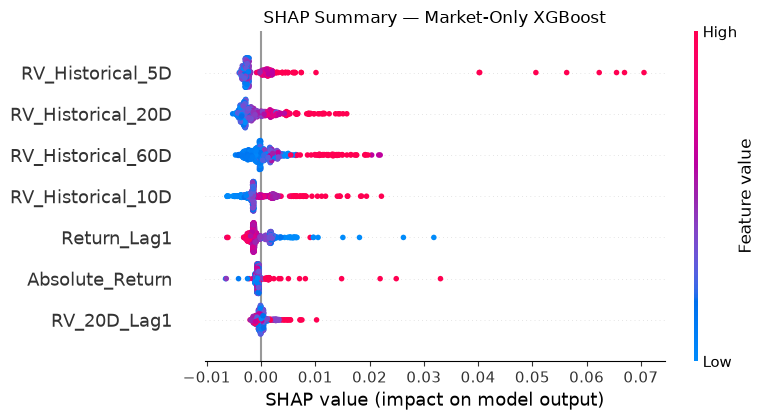

In [18]:
# ============================================================
# MARKET-ONLY SHAP SUMMARY
# ============================================================

import matplotlib.pyplot as plt

shap.summary_plot(
    market_shap_values.values,
    X_market_test,
    show=False
)

plt.title(
    "SHAP Summary — Market-Only XGBoost"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_market_only_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

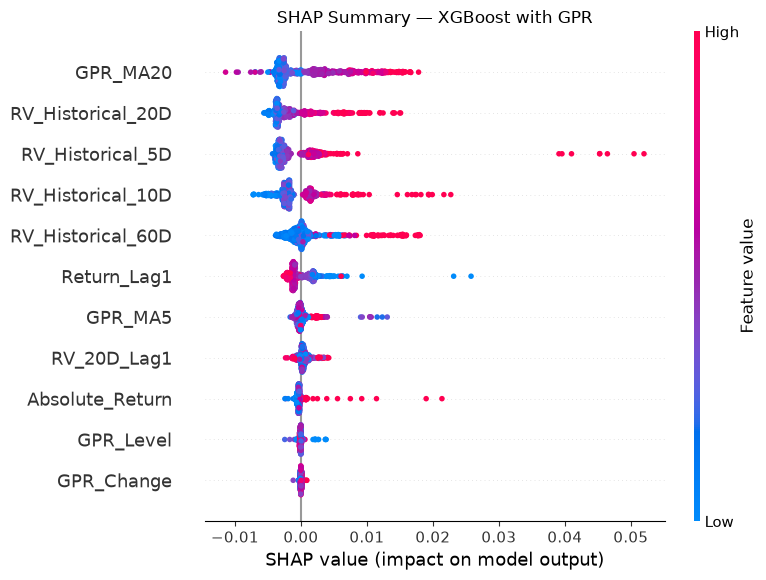

In [19]:
# ============================================================
# MARKET + GPR SHAP SUMMARY
# ============================================================

shap.summary_plot(
    gpr_shap_values.values,
    X_gpr_test,
    show=False
)

plt.title(
    "SHAP Summary — XGBoost with GPR"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_market_gpr_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# ============================================================
# MARKET FEATURE IMPORTANCE
# ============================================================

market_importance = pd.DataFrame({
    "Feature": MARKET_FEATURES,
    "Mean_Absolute_SHAP": np.abs(
        market_shap_values.values
    ).mean(axis=0)
})

market_importance = (
    market_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(market_importance)

market_importance.to_csv(
    TABLES_DIR / "shap_market_feature_importance.csv",
    index=False
)

,Feature,Mean_Absolute_SHAP
0,RV_Historical_5D,0.003010
1,RV_Historical_20D,0.002825
2,RV_Historical_60D,0.002542
3,RV_Historical_10D,0.002289
4,Return_Lag1,0.001832
5,Absolute_Return,0.000861
6,RV_20D_Lag1,0.000678


In [22]:
# ============================================================
# GPR FEATURE IMPORTANCE
# ============================================================

all_gpr_features = (
    MARKET_FEATURES + GPR_FEATURES
)

gpr_importance = pd.DataFrame({
    "Feature": all_gpr_features,
    "Mean_Absolute_SHAP": np.abs(
        gpr_shap_values.values
    ).mean(axis=0)
})

gpr_importance = (
    gpr_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(gpr_importance)

gpr_importance.to_csv(
    TABLES_DIR / "shap_gpr_feature_importance.csv",
    index=False
)

,Feature,Mean_Absolute_SHAP
0,GPR_MA20,0.004328
1,RV_Historical_20D,0.003242
2,RV_Historical_5D,0.003216
3,RV_Historical_10D,0.002761
4,RV_Historical_60D,0.002107
5,Return_Lag1,0.001502
6,GPR_MA5,0.000632
7,RV_20D_Lag1,0.000581
8,Absolute_Return,0.000500
9,GPR_Level,0.000143


In [23]:
# ============================================================
# GPR SHAP ATTRIBUTION SHARE
# ============================================================

total_importance = (
    gpr_importance["Mean_Absolute_SHAP"].sum()
)

gpr_total_importance = (
    gpr_importance.loc[
        gpr_importance["Feature"].isin(
            GPR_FEATURES
        ),
        "Mean_Absolute_SHAP"
    ].sum()
)

gpr_importance_share = (
    gpr_total_importance
    / total_importance
) * 100

print("=" * 60)
print("GPR SHAP ATTRIBUTION ANALYSIS")
print("=" * 60)

print(
    f"Total mean absolute SHAP: "
    f"{total_importance:.6f}"
)

print(
    f"GPR mean absolute SHAP: "
    f"{gpr_total_importance:.6f}"
)

print(
    f"GPR attribution share: "
    f"{gpr_importance_share:.2f}%"
)

GPR SHAP ATTRIBUTION ANALYSIS
Total mean absolute SHAP: 0.019093
GPR mean absolute SHAP: 0.005185
GPR attribution share: 27.15%
